In [1]:
!pip -q install -U xgboost lightgbm
import os
import random
import math
import time
import copy
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (accuracy_score,precision_recall_fscore_support,classification_report,confusion_matrix,roc_auc_score,roc_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier,GradientBoostingClassifier,ExtraTreesClassifier,HistGradientBoostingClassifier)
from scipy.stats import wilcoxon
#from statsmodels.stats.multitest import multipletests
import xgboost as xgb
import lightgbm as lgb
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
from google.colab import files
print("Please upload BOTH files:")
print("  1. KDDTrain.txt")
print("  2. KDDTest.txt")
print()
uploaded = files.upload()
print("\nUploaded files:")
for filename in uploaded.keys():print(" -", filename)
if "KDDTrain.txt" in uploaded:
    TRAIN_PATH = "/content/KDDTrain.txt"
elif "KDDTrain+.txt" in uploaded:
    TRAIN_PATH = "/content/KDDTrain+.txt"
else:
    raise FileNotFoundError(
        "Training file not found. Please upload KDDTrain.txt "
        "or KDDTrain+.txt")

if "KDDTest.txt" in uploaded:
    TEST_PATH = "/content/KDDTest.txt"
elif "KDDTest+.txt" in uploaded:
    TEST_PATH = "/content/KDDTest+.txt"
else:
    raise FileNotFoundError(
        "Testing file not found. Please upload KDDTest.txt "
        "or KDDTest+.txt")

print("\nDataset files located successfully:")
print("Train:", TRAIN_PATH)
print("Test :", TEST_PATH)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 45.8 MB/s eta 0:00:00
Device: cuda
Please upload BOTH files:
  1. KDDTrain.txt
  2. KDDTest.txt



Saving KDDTest+.txt to KDDTest+.txt
Saving KDDTrain+.txt to KDDTrain+.txt

Uploaded files:
 - KDDTest+.txt
 - KDDTrain+.txt

Dataset files located successfully:
Train: /content/KDDTrain+.txt
Test : /content/KDDTest+.txt


In [6]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

FEATURES = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land","wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised","root_shell","su_attempted","num_root","num_file_creations","num_shells","num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count","srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate"]
COLS = FEATURES + ["label", "difficulty"]

train_raw = pd.read_csv(TRAIN_PATH, header=0, names=COLS)
test_raw = pd.read_csv(TEST_PATH, header=0, names=COLS)

for df in (train_raw, test_raw):
    df["label"] = df["label"].astype(str).str.strip().str.lower().str.replace(r"\.$", "", regex=True)

before = len(train_raw)
train_raw = train_raw.drop_duplicates().reset_index(drop=True)

ATTACK_MAP = {
    "normal":"Normal",
    "back":"DoS", "land":"DoS", "neptune":"DoS", "pod":"DoS", "smurf":"DoS", "teardrop":"DoS", "apache2":"DoS", "udpstorm":"DoS", "processtable":"DoS", "mailbomb":"DoS",
    "ipsweep":"Probe", "nmap":"Probe", "portsweep":"Probe", "satan":"Probe", "mscan":"Probe", "saint":"Probe",
    "ftp_write":"R2L", "guess_passwd":"R2L", "imap":"R2L", "multihop":"R2L", "phf":"R2L", "spy":"R2L", "warezclient":"R2L", "warezmaster":"R2L", "sendmail":"R2L", "named":"R2L", "snmpgetattack":"R2L", "snmpguess":"R2L", "xlock":"R2L", "xsnoop":"R2L", "httptunnel":"R2L", "worm":"R2L",
    "buffer_overflow":"U2R", "loadmodule":"U2R", "perl":"U2R", "rootkit":"U2R", "sqlattack":"U2R", "xterm":"U2R", "ps":"U2R"
}
ATTACK_MAP.update({"dos": "DoS", "probe": "Probe","r2l": "R2L","u2r": "U2R"})
train_raw["class_name"] = train_raw["label"].map(ATTACK_MAP)
test_raw["class_name"] = test_raw["label"].map(ATTACK_MAP)

unknown_train = sorted(train_raw.loc[train_raw["class_name"].isna(), "label"].unique())
unknown_test = sorted(test_raw.loc[test_raw["class_name"].isna(), "label"].unique())

print("Unknown training labels:", unknown_train)
print("Unknown testing labels:", unknown_test)

if unknown_train or unknown_test:
    raise ValueError(f"Unmapped labels: train={unknown_train}, test={unknown_test}")

CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {i: name for name, i in CLASS_TO_ID.items()}

y_train = train_raw["class_name"].map(CLASS_TO_ID).to_numpy(dtype=np.int64)
y_test = test_raw["class_name"].map(CLASS_TO_ID).to_numpy(dtype=np.int64)

Xtr_df = train_raw[FEATURES].copy()
Xte_df = test_raw[FEATURES].copy()
CAT_COLS = ["protocol_type", "service", "flag"]
encoders = {}

for col in CAT_COLS:
    tr = Xtr_df[col].astype(str).str.strip()
    te = Xte_df[col].astype(str).str.strip()
    encoders[col] = {v: i for i, v in enumerate(sorted(tr.unique()))}
    Xtr_df[col] = tr.map(encoders[col]).astype(np.float32)
    Xte_df[col] = te.map(encoders[col]).fillna(len(encoders[col])).astype(np.float32)
    print(f"{col}: {len(encoders[col])} training categories")

X_train_raw = Xtr_df.to_numpy(dtype=np.float32)
X_test_raw = Xte_df.to_numpy(dtype=np.float32)

if not np.isfinite(X_train_raw).all() or not np.isfinite(X_test_raw).all():
    raise ValueError("Features contain NaN or infinite values.")

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

assert X_train.shape == (len(y_train), 41) and X_test.shape == (len(y_test), 41)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

distribution_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Training_Count": pd.Series(y_train).map(ID_TO_CLASS).value_counts().reindex(CLASS_NAMES, fill_value=0).to_numpy(),
    "Testing_Count": pd.Series(y_test).map(ID_TO_CLASS).value_counts().reindex(CLASS_NAMES, fill_value=0).to_numpy()
})


Unknown training labels: []
Unknown testing labels: []
protocol_type: 3 training categories
service: 70 training categories
flag: 11 training categories


In [7]:
# ============================================================
# AUTOENCODER WITH TRAINING + VALIDATION LOSS
# Test data remains completely untouched
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

class Autoencoder(nn.Module):
    def __init__(self, input_dim=41, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32), nn.ReLU(),
            nn.Linear(32, 64), nn.ReLU(),
            nn.Linear(64, input_dim), nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

# -----------------------------
# Hyperparameters
# -----------------------------
AE_EPOCHS = 50
AE_BATCH = 32
AE_LR = 1e-3
LATENT_DIM = 16
AE_VAL_SIZE = 0.20

X_ae_train, X_ae_val = train_test_split(X_train, test_size=AE_VAL_SIZE, random_state=42, shuffle=True)
train_tensor = torch.from_numpy(X_ae_train.astype(np.float32))
val_tensor = torch.from_numpy(X_ae_val.astype(np.float32))
loader_ae_train = DataLoader(TensorDataset(train_tensor),batch_size=AE_BATCH,shuffle=True,pin_memory=torch.cuda.is_available())
loader_ae_val = DataLoader(TensorDataset(val_tensor), batch_size=AE_BATCH,shuffle=False,pin_memory=torch.cuda.is_available())

ae = Autoencoder(X_train.shape[1], LATENT_DIM).to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=AE_LR)
criterion_ae = nn.MSELoss()
ae_history = {"train_loss": [], "val_loss": []}

for epoch in range(AE_EPOCHS):
    ae.train()
    train_total = 0.0

    for (xb,) in loader_ae_train:
        xb = xb.to(DEVICE, non_blocking=True)
        opt_ae.zero_grad(set_to_none=True)
        xhat, _ = ae(xb)
        loss = criterion_ae(xhat, xb)
        loss.backward()
        opt_ae.step()
        train_total += loss.item() * len(xb)
    train_loss = train_total / len(loader_ae_train.dataset)

    # ===== Validation =====
    ae.eval()
    val_total = 0.0

    with torch.no_grad():
        for (xb,) in loader_ae_val:
            xb = xb.to(DEVICE, non_blocking=True)
            xhat, _ = ae(xb)
            loss = criterion_ae(xhat, xb)
            val_total += loss.item() * len(xb)

    val_loss = val_total / len(loader_ae_val.dataset)
    ae_history["train_loss"].append(train_loss)
    ae_history["val_loss"].append(val_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1:03d}/{AE_EPOCHS} | "f"Train Loss = {train_loss:.6f} | "f"Val Loss = {val_loss:.6f}")
best_epoch = np.argmin(ae_history["val_loss"]) + 1
best_val_loss = np.min(ae_history["val_loss"])

ae.eval()
with torch.no_grad():
    Z_train = ae.encoder(torch.from_numpy(X_train.astype(np.float32)).to(DEVICE)).cpu().numpy().astype(np.float32)
latent_scaler = MinMaxScaler()
Z_train_n = latent_scaler.fit_transform(Z_train).astype(np.float32)

Epoch 001/50 | Train Loss = 0.011458 | Val Loss = 0.003827
Epoch 005/50 | Train Loss = 0.000980 | Val Loss = 0.000892
Epoch 010/50 | Train Loss = 0.000543 | Val Loss = 0.000550
Epoch 015/50 | Train Loss = 0.000422 | Val Loss = 0.000408
Epoch 020/50 | Train Loss = 0.000354 | Val Loss = 0.000354
Epoch 025/50 | Train Loss = 0.000325 | Val Loss = 0.000331
Epoch 030/50 | Train Loss = 0.000302 | Val Loss = 0.000290
Epoch 035/50 | Train Loss = 0.000291 | Val Loss = 0.000297
Epoch 040/50 | Train Loss = 0.000279 | Val Loss = 0.000321
Epoch 045/50 | Train Loss = 0.000274 | Val Loss = 0.000332
Epoch 050/50 | Train Loss = 0.000263 | Val Loss = 0.000262


In [8]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim=41, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 64), nn.ReLU(),nn.Linear(64, 32), nn.ReLU(),nn.Linear(32, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 32), nn.ReLU(),nn.Linear(32, 64), nn.ReLU(),nn.Linear(64, input_dim), nn.Sigmoid())

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

AE_EPOCHS = 100
AE_BATCH = 32
AE_LR = 1e-3
LATENT_DIM = 16

ae = Autoencoder(X_train.shape[1], LATENT_DIM).to(DEVICE)
opt_ae = torch.optim.Adam(ae.parameters(), lr=AE_LR)
criterion_ae = nn.MSELoss()

loader_ae = DataLoader(TensorDataset(torch.from_numpy(X_train)),batch_size=AE_BATCH,shuffle=True,pin_memory=torch.cuda.is_available())
ae_history = {"train_loss": []}

for epoch in range(AE_EPOCHS):
    ae.train()
    total = 0.0

    for (xb,) in loader_ae:
        xb = xb.to(DEVICE)
        opt_ae.zero_grad(set_to_none=True)
        xhat, _ = ae(xb)
        loss = criterion_ae(xhat, xb)
        loss.backward()
        opt_ae.step()
        total += loss.item() * len(xb)

    train_loss = total / len(loader_ae.dataset)
    ae_history["train_loss"].append(train_loss)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"Epoch {epoch + 1:03d}/{AE_EPOCHS} | Train Loss = {train_loss:.6f}")

ae.eval()
with torch.no_grad():
    Z_train = ae.encoder(torch.from_numpy(X_train).to(DEVICE)).cpu().numpy().astype(np.float32)
latent_scaler = MinMaxScaler()
Z_train_n = latent_scaler.fit_transform(Z_train).astype(np.float32)

with torch.no_grad():
    X_recon = ae.decoder(torch.from_numpy(Z_train).to(DEVICE)).cpu().numpy()
recon_error = np.mean((X_train - X_recon) ** 2, axis=1)

print("AUTOENCODER TRAINING COMPLETED")

Epoch 001/100 | Train Loss = 0.010468
Epoch 005/100 | Train Loss = 0.001204
Epoch 010/100 | Train Loss = 0.000711
Epoch 015/100 | Train Loss = 0.000599
Epoch 020/100 | Train Loss = 0.000352
Epoch 025/100 | Train Loss = 0.000327
Epoch 030/100 | Train Loss = 0.000305
Epoch 035/100 | Train Loss = 0.000294
Epoch 040/100 | Train Loss = 0.000286
Epoch 045/100 | Train Loss = 0.000270
Epoch 050/100 | Train Loss = 0.000267
Epoch 055/100 | Train Loss = 0.000260
Epoch 060/100 | Train Loss = 0.000123
Epoch 065/100 | Train Loss = 0.000107
Epoch 070/100 | Train Loss = 0.000109
Epoch 075/100 | Train Loss = 0.000104
Epoch 080/100 | Train Loss = 0.000105
Epoch 085/100 | Train Loss = 0.000097
Epoch 090/100 | Train Loss = 0.000093
Epoch 095/100 | Train Loss = 0.000095
Epoch 100/100 | Train Loss = 0.000084
AUTOENCODER TRAINING COMPLETED


In [9]:
models = OrderedDict([
    ("LR", LogisticRegression(max_iter=500, solver="lbfgs", random_state=SEED)),
    ("KNN", KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
    ("RF", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("GB", GradientBoostingClassifier(n_estimators=200, random_state=SEED)),
    ("Extra Trees", ExtraTreesClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
    ("XGBoost", xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,subsample=0.9, colsample_bytree=0.9,objective="multi:softprob", num_class=5,eval_metric="mlogloss", tree_method="hist",random_state=SEED, n_jobs=-1)),
    ("LightGBM", lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,objective="multiclass", num_class=5,random_state=SEED, n_jobs=-1, verbosity=-1)),
    ("HGBoosting", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=SEED))])


Logistic Regression
              precision    recall  f1-score   support

      Normal     0.8078    0.9416    0.8696     20083
         DoS     0.9251    0.7641    0.8369     13825
       Probe     0.8311    0.6921    0.7552      3540
         R2L     0.0625    0.0031    0.0058       327
         U2R     0.0000    0.0000    0.0000        17

    accuracy                         0.8448     37792
   macro avg     0.5253    0.4802    0.4935     37792
weighted avg     0.8461    0.8448    0.8391     37792

Accuracy=0.8448 | Macro Precision=0.5253 | Macro Recall=0.4802 | Macro F1=0.4935
Confusion Matrix:
 [[18911   755   402    15     0]
 [ 3169 10563    93     0     0]
 [  992    98  2450     0     0]
 [  323     0     3     1     0]
 [   15     2     0     0     0]]
Macro ROC-AUC (OvR) = 0.8860

KNN
              precision    recall  f1-score   support

      Normal     0.8254    0.9771    0.8949     20083
         DoS     0.9631    0.8016    0.8750     13825
       Probe     0.7691    

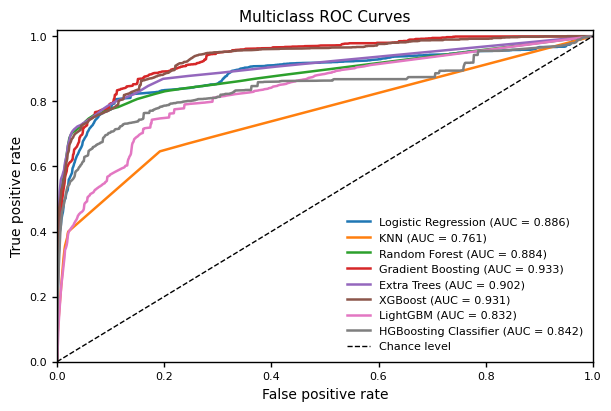

In [10]:
import os, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, roc_auc_score
from sklearn.preprocessing import label_binarize

CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
N_CLASSES = len(CLASS_NAMES)
RESULT_DIR = "PLOS_ONE_Classifier_Figures"
os.makedirs(RESULT_DIR, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "axes.linewidth": 0.8, "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 600})
roc_results, summary_results = {}, []
y_test_array = np.asarray(y_test).astype(int)
y_test_bin = label_binarize(y_test_array, classes=np.arange(N_CLASSES))

ae.eval()
with torch.no_grad():
    Z_test = ae.encoder(torch.from_numpy(X_test).to(DEVICE)).cpu().numpy().astype(np.float32)
Z_test_n = latent_scaler.transform(Z_test).astype(np.float32)

def evaluate_classifier(model_name, model):
    model.fit(Z_train_n, y_train)
    y_pred = model.predict(Z_test_n)
    safe = "".join(c if c.isalnum() or c in "-_" else "_" for c in model_name.replace(" ", "_"))
    report = classification_report(y_test_array, y_pred, labels=np.arange(N_CLASSES), target_names=CLASS_NAMES, digits=4, zero_division=0)
    print(f"\n{'='*65}\n{model_name}\n{'='*65}\n{report}")
    with open(os.path.join(RESULT_DIR, f"{safe}_Report.txt"), "w", encoding="utf-8") as f: f.write(report)
    acc = accuracy_score(y_test_array, y_pred)
    prec = precision_score(y_test_array, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_test_array, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_test_array, y_pred, average="macro", zero_division=0)
    cm = confusion_matrix(y_test_array, y_pred, labels=np.arange(N_CLASSES))
    print(f"Accuracy={acc:.4f} | Macro Precision={prec:.4f} | Macro Recall={rec:.4f} | Macro F1={f1:.4f}")
    print("Confusion Matrix:\n", cm)
    fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True, square=True, linewidths=0, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 9}, ax=ax)
    ax.set_xlabel("Predicted class", labelpad=8)
    ax.set_ylabel("True class", labelpad=8)
    ax.set_title(f"{model_name}", pad=10, fontweight="bold")
    ax.tick_params(axis="x", rotation=25, length=3)
    ax.tick_params(axis="y", rotation=0, length=3)
    fig.savefig(os.path.join(RESULT_DIR, f"{safe}_ConfusionMatrix.png"), dpi=600, bbox_inches="tight")
    fig.savefig(os.path.join(RESULT_DIR, f"{safe}_ConfusionMatrix.tiff"), dpi=600, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(os.path.join(RESULT_DIR, f"{safe}_ConfusionMatrix.pdf"), bbox_inches="tight")
    plt.close(fig)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(os.path.join(RESULT_DIR, f"{safe}_ConfusionMatrix.csv"))

    auc_macro = np.nan
    try:
        if hasattr(model, "predict_proba"): scores = model.predict_proba(Z_test_n)
        elif hasattr(model, "decision_function"): scores = model.decision_function(Z_test_n)
        else: raise ValueError("Classifier has no probability or decision scores.")
        scores = np.asarray(scores)
        if scores.ndim != 2 or scores.shape[1] != N_CLASSES: raise ValueError(f"Expected 5 score columns; received {scores.shape}.")
        classes = np.asarray(model.classes_).astype(int)
        scores = scores[:, [np.where(classes == c)[0][0] for c in range(N_CLASSES)]]
        auc_macro = roc_auc_score(y_test_bin, scores, average="macro", multi_class="ovr")
        fpr_grid = np.linspace(0, 1, 1001)
        tpr_classes = [np.interp(fpr_grid, *roc_curve(y_test_bin[:, i], scores[:, i])[:2]) for i in range(N_CLASSES)]
        mean_tpr = np.mean(tpr_classes, axis=0)
        mean_tpr[0], mean_tpr[-1] = 0.0, 1.0
        roc_results[model_name] = {"fpr": fpr_grid, "tpr": mean_tpr, "auc": auc_macro}
        print(f"Macro ROC-AUC (OvR) = {auc_macro:.4f}")
        pd.DataFrame(scores, columns=[f"Score_{c}" for c in CLASS_NAMES]).to_csv(os.path.join(RESULT_DIR, f"{safe}_ROCScores.csv"), index=False)
    except (ValueError, AttributeError, IndexError) as e: print(f"ROC unavailable for {model_name}: {e}")
    result = {"Model": model_name, "Accuracy": acc, "Macro Precision": prec, "Macro Recall": rec, "Macro F1": f1, "Macro ROC-AUC (OvR)": auc_macro}
    summary_results.append(result)
    return result

def plot_all_roc():
    if not roc_results: print("No ROC curves available. Evaluate classifiers first."); return
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    colors = plt.get_cmap("tab10").colors
    for i, (name, r) in enumerate(roc_results.items()): ax.plot(r["fpr"], r["tpr"], color=colors[i % len(colors)], linewidth=1.8, label=f'{name} (AUC = {r["auc"]:.3f})')
    ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.0, label="Chance level")
    ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False positive rate", ylabel="True positive rate", title="Multiclass ROC Curves")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.0)
    ax.tick_params(axis="both", direction="out", width=1.0)
    ax.legend(loc="lower right", frameon=False, fontsize=8)
    fig.savefig(os.path.join(RESULT_DIR, "All_Classifiers_ROC.png"), dpi=600, bbox_inches="tight")
    fig.savefig(os.path.join(RESULT_DIR, "All_Classifiers_ROC.tiff"), dpi=600, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
    fig.savefig(os.path.join(RESULT_DIR, "All_Classifiers_ROC.pdf"), bbox_inches="tight")
    plt.show()
    plt.close(fig)
    pd.DataFrame([{"Model": n, "Macro ROC-AUC (OvR)": r["auc"]} for n, r in roc_results.items()]).to_csv(os.path.join(RESULT_DIR, "ROC_AUC_Summary.csv"), index=False)
# ============================================================
# CALL YOUR CLASSIFIERS
# ============================================================
evaluate_classifier("Logistic Regression", models["LR"])
evaluate_classifier("KNN",models["KNN"])
evaluate_classifier("Random Forest", models["RF"])
evaluate_classifier("Gradient Boosting",models['GB'] )
evaluate_classifier("Extra Trees", models["Extra Trees"])
evaluate_classifier("XGBoost", models["XGBoost"])
evaluate_classifier("LightGBM", models["LightGBM"])
evaluate_classifier("HGBoosting Classifier", models["HGBoosting"])

plot_all_roc()
pd.DataFrame(summary_results).to_csv(os.path.join(RESULT_DIR, "Classifier_Performance_Summary.csv"), index=False)